# Visualizaciones del sistema ECOBICI

Este módulo transforma los datos disponibles en **preguntas de investigación descriptivas**. Cada visualización responde una pregunta concreta y se acompaña de una interpretación basada en los datos, su relevancia y sus limitaciones.

**Fuentes**
- `Viajes diarios del sistema Ecobici.csv`: evolución diaria por género (2010–2024).
- `Viajes mensuales desglosados del sistema Ecobici.csv`: viajes por hora, género y rango de edad (2010–2024).
- `Viajes Ecobico 2026-01.csv`: viajes individuales con estación, fecha y hora de retiro/arribo (enero de 2026).
- `Ubicación de estaciones ecobici.csv`: ubicación, alcaldía, tipo y capacidad de estaciones.




## Objetivos

1. Identificar tendencias de largo plazo y estacionalidad.
2. Describir diferencias por día, hora, género y edad.
3. Analizar distribución y capacidad de infraestructura.
4. Detectar estaciones, rutas y desequilibrios operativos en enero de 2026.
5. Analizar duración sin dejar que registros temporalmente anómalos distorsionen las métricas.


In [1]:
from pathlib import Path
from IPython.display import display, Markdown
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

COL = {'verde':'#2A9D8F','azul':'#457B9D','amarillo':'#E9C46A','naranja':'#F4A261','rojo':'#E76F51','morado':'#7B6DCC'}
plt.rcParams.update({'figure.figsize':(11,5.5),'axes.titlesize':14,'axes.labelsize':11,'figure.dpi':110})

# Los notebooks están en la raíz del repositorio y los CSV en ./Datasets/.
# Se admiten ejecuciones desde la raíz, Datasets o una subcarpeta.
def buscar_archivo(nombre):
    cwd = Path.cwd().resolve()
    directorios = [cwd, *cwd.parents]
    candidatos = []
    for raiz in directorios:
        candidatos.extend([raiz / 'Datasets' / nombre,
                           raiz / 'datasets' / nombre,
                           raiz / nombre])
    for ruta in candidatos:
        if ruta.is_file():
            return ruta
    revisados = '\n'.join(str(p) for p in candidatos[:12])
    raise FileNotFoundError(
        f'No se encontró el archivo: {nombre}\n'
        f'Directorio de ejecución: {cwd}\n'
        f'Se esperaba en la carpeta Datasets del proyecto.\n'
        f'Ubicaciones verificadas (primeras 12):\n{revisados}'
    )

ARCHIVOS = {
    'estaciones': buscar_archivo('Ubicación de estaciones ecobici.csv'),
    'diarios': buscar_archivo('Viajes diarios del sistema Ecobici.csv'),
    'detalle_2026': buscar_archivo('Viajes Ecobici 2026-01.csv'),
    'mensuales': buscar_archivo('Viajes mensuales desglosados del sistema Ecobici.csv'),
}
print('Directorio de trabajo:', Path.cwd().resolve())
for clave, ruta in ARCHIVOS.items():
    print(f'{clave:12s} -> {ruta}')


Directorio de trabajo: C:\Users\jgallegos\Desktop\Proyecto Modulo I\Movilidad-Urbana-del-Sistema-de-Transporte-CDMX
estaciones   -> C:\Users\jgallegos\Desktop\Proyecto Modulo I\Movilidad-Urbana-del-Sistema-de-Transporte-CDMX\Datasets\Ubicación de estaciones ecobici.csv
diarios      -> C:\Users\jgallegos\Desktop\Proyecto Modulo I\Movilidad-Urbana-del-Sistema-de-Transporte-CDMX\Datasets\Viajes diarios del sistema Ecobici.csv
detalle_2026 -> C:\Users\jgallegos\Desktop\Proyecto Modulo I\Movilidad-Urbana-del-Sistema-de-Transporte-CDMX\Datasets\Viajes Ecobici 2026-01.csv
mensuales    -> C:\Users\jgallegos\Desktop\Proyecto Modulo I\Movilidad-Urbana-del-Sistema-de-Transporte-CDMX\Datasets\Viajes mensuales desglosados del sistema Ecobici.csv


## 1. Preparación para visualizar

La limpieza exhaustiva corresponde a su módulo específico. Aquí solo se crean tipos y variables derivadas indispensables para las visualizaciones; las fuentes originales no se modifican.


In [2]:
diarios = pd.read_csv(ARCHIVOS['diarios'], low_memory=False)
mensuales = pd.read_csv(ARCHIVOS['mensuales'], low_memory=False)
estaciones = pd.read_csv(ARCHIVOS['estaciones'], low_memory=False)

diarios['fecha'] = pd.to_datetime(diarios['fecha'], errors='coerce')
diarios['genero'] = diarios['genero'].fillna('No especificado')
dias_es = {0:'Lunes',1:'Martes',2:'Miércoles',3:'Jueves',4:'Viernes',5:'Sábado',6:'Domingo'}

mensuales['fecha_corte'] = pd.to_datetime(mensuales['fecha_corte'], errors='coerce')
mensuales['genero'] = mensuales['genero'].fillna('No especificado')
mensuales['hora_num'] = pd.to_numeric(mensuales['hora'].astype(str).str.extract(r'(^\d{1,2})')[0], errors='coerce')
mensuales['rango_edad_std'] = (mensuales['rango_edad'].astype('string').str.replace(r'\s*-\s*','-',regex=True).str.strip().fillna('No especificado'))

estaciones['estacion_id'] = pd.to_numeric(estaciones['num_cicloestacion'], errors='coerce').astype('Int64').astype('string')
# Identificador y descripción para etiquetar las estaciones en los gráficos.
# Si el catálogo no incluye un nombre, se utiliza el identificador.
columnas_nombre = [c for c in estaciones.columns if c.lower() in {
    'nombre', 'nombre_estacion', 'nombre_cicloestacion', 'cicloestacion',
    'estacion', 'direccion', 'ubicacion', 'ubicación'
}]
if columnas_nombre:
    nombre_map = (estaciones.dropna(subset=['estacion_id'])
                  .drop_duplicates('estacion_id')
                  .set_index('estacion_id')[columnas_nombre[0]]
                  .astype('string').to_dict())
else:
    nombre_map = {}


resumen = pd.DataFrame({'fuente':['Viajes diarios','Viajes mensuales','Estaciones'],
                        'filas':[len(diarios),len(mensuales),len(estaciones)],
                        'columnas':[diarios.shape[1],mensuales.shape[1],estaciones.shape[1]]})
display(resumen)


,fuente,filas,columnas
0,Viajes diarios,12261,5
1,Viajes mensuales,115773,9
2,Estaciones,480,12


In [3]:
cols = ['Genero_Usuario','Edad_Usuario','Ciclo_Estacion_Retiro','Fecha_Retiro','Hora_Retiro','Ciclo_EstacionArribo','Fecha_Arribo','Hora_Arribo']
detalle = pd.read_csv(ARCHIVOS['detalle_2026'], usecols=cols,
                      dtype={'Genero_Usuario':'string','Ciclo_Estacion_Retiro':'string','Ciclo_EstacionArribo':'string'},
                      low_memory=False)
detalle['Edad_Usuario'] = pd.to_numeric(detalle['Edad_Usuario'], errors='coerce')
detalle['retiro_dt'] = pd.to_datetime(detalle['Fecha_Retiro'].astype(str)+' '+detalle['Hora_Retiro'].astype(str), dayfirst=True, errors='coerce')
detalle['arribo_dt'] = pd.to_datetime(detalle['Fecha_Arribo'].astype(str)+' '+detalle['Hora_Arribo'].astype(str), dayfirst=True, errors='coerce')
detalle['duracion_min'] = (detalle['arribo_dt']-detalle['retiro_dt']).dt.total_seconds()/60

def id_est(s): return pd.to_numeric(s, errors='coerce').astype('Int64').astype('string')
detalle['origen_id'] = id_est(detalle['Ciclo_Estacion_Retiro'])
detalle['destino_id'] = id_est(detalle['Ciclo_EstacionArribo'])
detalle['hora_retiro'] = detalle['retiro_dt'].dt.hour

gmap={'M':'Hombre','F':'Mujer','O':'Otro','?':'No especificado'}
detalle['genero_std'] = detalle['Genero_Usuario'].map(gmap).fillna('No especificado')
es_enero = detalle['arribo_dt'].dt.to_period('M').eq(pd.Period('2026-01'))
duracion_valida = es_enero & detalle['duracion_min'].between(1,180,inclusive='both')
detalle_duracion = detalle.loc[duracion_valida].copy()

display(pd.DataFrame({'métrica':['Registros','Arribos enero 2026','Duraciones 1-180 min','Excluidos solo de duración'],
                      'valor':[len(detalle),int(es_enero.sum()),len(detalle_duracion),int((~duracion_valida).sum())]}))
print('Retiros:',detalle.retiro_dt.min(),'a',detalle.retiro_dt.max())
print('Arribos:',detalle.arribo_dt.min(),'a',detalle.arribo_dt.max())


,métrica,valor
0,Registros,1525302
1,Arribos enero 2026,1525302
2,Duraciones 1-180 min,1524562
3,Excluidos solo de duración,740


Retiros: 2025-08-02 23:24:30 a 2026-01-31 23:54:49
Arribos: 2026-01-01 00:00:16 a 2026-01-31 23:59:51


---
## Pregunta 1 · ¿Cómo ha evolucionado el número de viajes de ECOBICI entre 2010 y 2024?

**Tipo:** línea temporal para identificar crecimiento, caídas y cambios de tendencia.


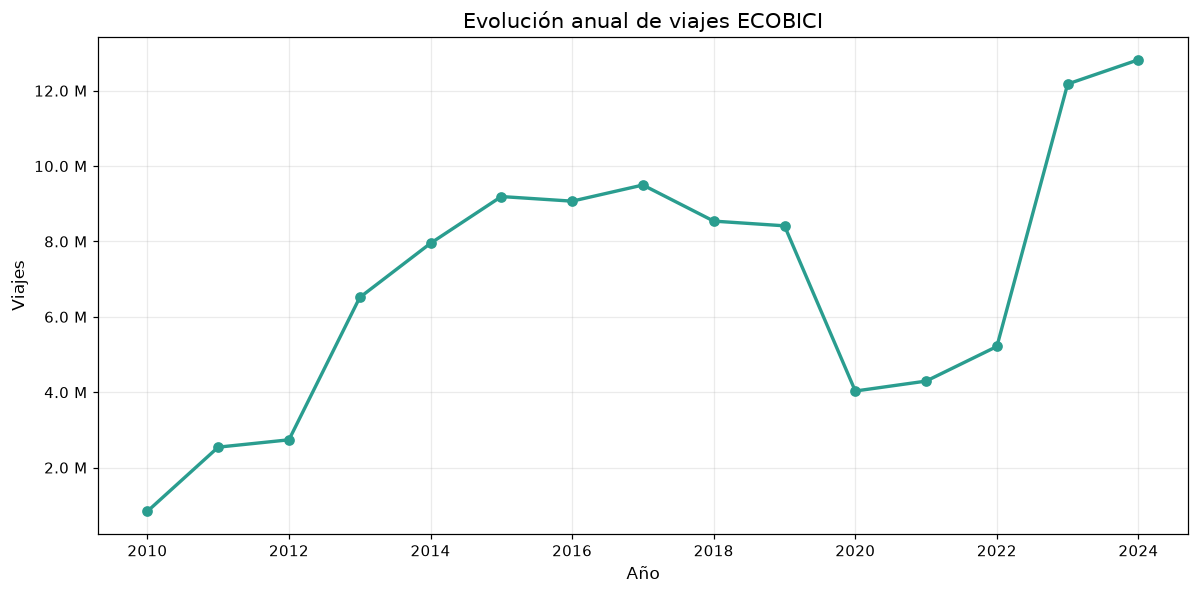

**Interpretación.** El mayor volumen anual observado se registra en **2024**, con **12.82 millones** de viajes. El último año observado es **2024**, con registros hasta **2024-07-31**; debe verificarse su cobertura antes de compararlo con años completos.  


In [12]:
viajes_anuales = diarios.assign(anio=diarios['fecha'].dt.year).groupby('anio', as_index=False)['viajes'].sum()
fig,ax=plt.subplots(); ax.plot(viajes_anuales.anio,viajes_anuales.viajes,marker='o',lw=2.2,color=COL['verde'])
ax.set(title='Evolución anual de viajes ECOBICI',xlabel='Año',ylabel='Viajes'); ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p:f'{x/1e6:.1f} M')); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
r=viajes_anuales.loc[viajes_anuales.viajes.idxmax()]; fin=viajes_anuales.iloc[-1]
display(Markdown(f"""**Interpretación.** El mayor volumen anual observado se registra en **{int(r.anio)}**, con **{r.viajes/1e6:.2f} millones** de viajes. El último año observado es **{int(fin.anio)}**, con registros hasta **{diarios.fecha.max().date()}**; debe verificarse su cobertura antes de compararlo con años completos.  
"""))


---
## Pregunta 2 · En 2024, ¿qué días de la semana concentran más viajes diarios?

**Tipo:** barras con promedio diario por día de la semana.


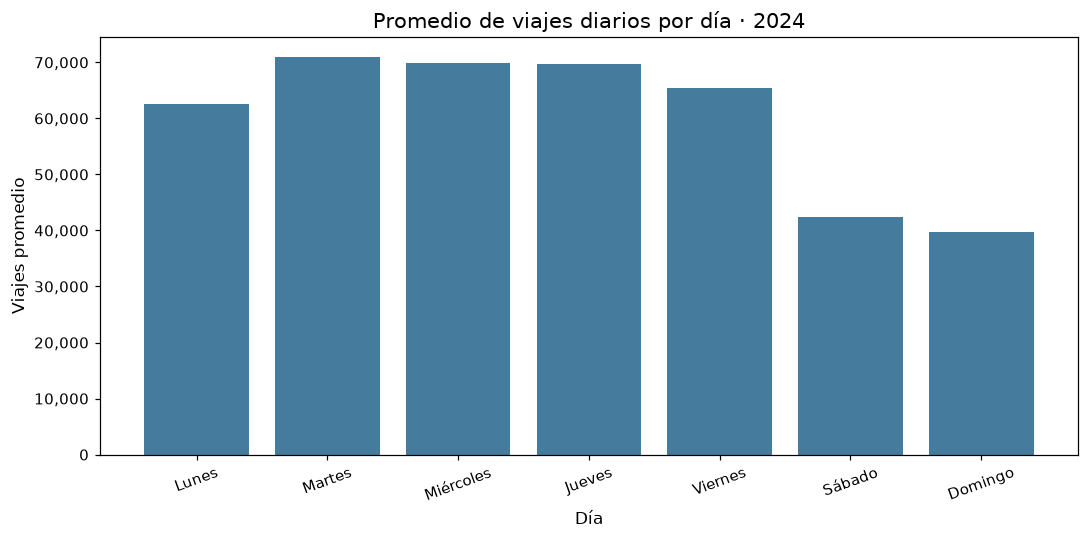

**Interpretación.** **Martes** presenta el mayor promedio (70,947) y **Domingo** el menor (39,650); la diferencia es **78.9%**.  
**Relevancia.** Distingue patrones laborales y de fin de semana.  
**Limitación.** La cobertura para 2024 debe verificarse: su última fecha registrada es 2024-07-31. Días festivos y días sin registro pueden modificar el promedio.

In [5]:
d2024=diarios[diarios.fecha.dt.year.eq(2024)].groupby('fecha',as_index=False).viajes.sum(); d2024['dia_num']=d2024.fecha.dt.dayofweek; d2024['dia']=d2024.dia_num.map(dias_es)
w=d2024.groupby(['dia_num','dia'],as_index=False).viajes.mean().sort_values('dia_num')
fig,ax=plt.subplots(figsize=(10,5)); ax.bar(w.dia,w.viajes,color=COL['azul']); ax.set(title='Promedio de viajes diarios por día · 2024',xlabel='Día',ylabel='Viajes promedio'); ax.tick_params(axis='x',rotation=20); ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}')); plt.tight_layout(); plt.show()
a=w.loc[w.viajes.idxmax()]; b=w.loc[w.viajes.idxmin()]; pct=(a.viajes/b.viajes-1)*100
display(Markdown(f"""**Interpretación.** **{a.dia}** presenta el mayor promedio ({a.viajes:,.0f}) y **{b.dia}** el menor ({b.viajes:,.0f}); la diferencia es **{pct:.1f}%**.  
**Relevancia.** Distingue patrones laborales y de fin de semana.  
**Limitación.** La cobertura para 2024 debe verificarse: su última fecha registrada es {d2024.fecha.max().date() if not d2024.empty else "no disponible"}. Días festivos y días sin registro pueden modificar el promedio."""))


---
## Pregunta 3 · ¿Cómo ha cambiado la composición de viajes por género?

**Tipo:** líneas de participación porcentual anual para comparar composición sin que domine el crecimiento total.


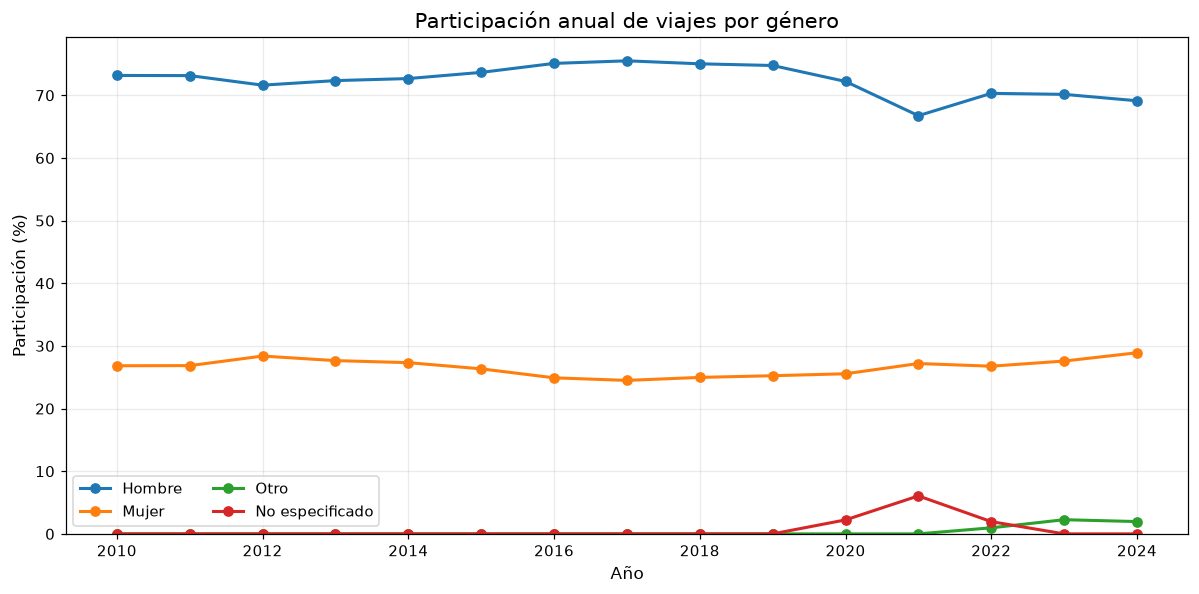

**Interpretación.** En 2024, la composición observada es **Hombre: 69.1%, Mujer: 28.9%, Otro: 2.0%, No especificado: 0.0%**.  
**Relevancia.** Permite ver si el crecimiento del sistema se acompaña de cambios en los grupos registrados.  
**Limitación.** Hay registros no especificados y la variable no permite inferir identidad, motivos de viaje ni barreras de acceso.

In [6]:
ga=diarios.assign(anio=diarios.fecha.dt.year).groupby(['anio','genero'],as_index=False).viajes.sum(); gp=ga.pivot(index='anio',columns='genero',values='viajes').fillna(0); sh=gp.div(gp.sum(axis=1),axis=0)*100
fig,ax=plt.subplots();
for col in [x for x in ['Hombre','Mujer','Otro','No especificado'] if x in sh.columns]: ax.plot(sh.index,sh[col],marker='o',lw=2,label=col)
ax.set(title='Participación anual de viajes por género',xlabel='Año',ylabel='Participación (%)'); ax.set_ylim(bottom=0); ax.legend(ncol=2); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
u=sh.loc[sh.index.max()].sort_values(ascending=False); txt=', '.join(f'{k}: {v:.1f}%' for k,v in u.items())
display(Markdown(f"""**Interpretación.** En {sh.index.max()}, la composición observada es **{txt}**.  
**Relevancia.** Permite ver si el crecimiento del sistema se acompaña de cambios en los grupos registrados.  
**Limitación.** Hay registros no especificados y la variable no permite inferir identidad, motivos de viaje ni barreras de acceso."""))


---
## Pregunta 4 · ¿Qué grupos de edad concentran más viajes en el histórico disponible?

**Tipo:** barras horizontales por rango de edad.


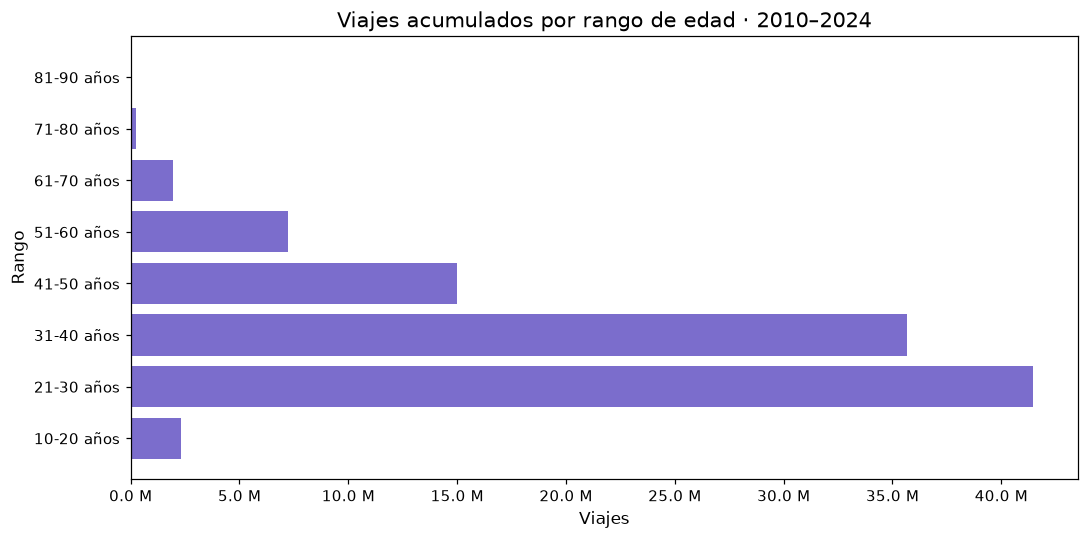

**Interpretación.** El rango **21-30 años** concentra el mayor volumen acumulado: **41.45 millones** de viajes.  
**Relevancia.** Identifica segmentos etarios con mayor presencia observada.  


In [13]:
eh=mensuales[mensuales.rango_edad_std.ne('No especificado')].groupby('rango_edad_std',as_index=False).viajes.sum()
def inicio(x):
    try:return int(str(x).split('-')[0])
    except:return 999
eh['orden']=eh.rango_edad_std.map(inicio); eh=eh.sort_values('orden')
fig,ax=plt.subplots(figsize=(10,5)); ax.barh(eh.rango_edad_std,eh.viajes,color=COL['morado']); ax.set(title='Viajes acumulados por rango de edad · 2010–2024',xlabel='Viajes',ylabel='Rango'); ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,p:f'{x/1e6:.1f} M')); plt.tight_layout(); plt.show()
r=eh.loc[eh.viajes.idxmax()]
display(Markdown(f"""**Interpretación.** El rango **{r.rango_edad_std}** concentra el mayor volumen acumulado: **{r.viajes/1e6:.2f} millones** de viajes.  
**Relevancia.** Identifica segmentos etarios con mayor presencia observada.  
"""))


---
## Pregunta 5 · ¿A qué horas se concentra la demanda y difiere el perfil horario por género?

**Tipo:** líneas por hora del día usando 2024.


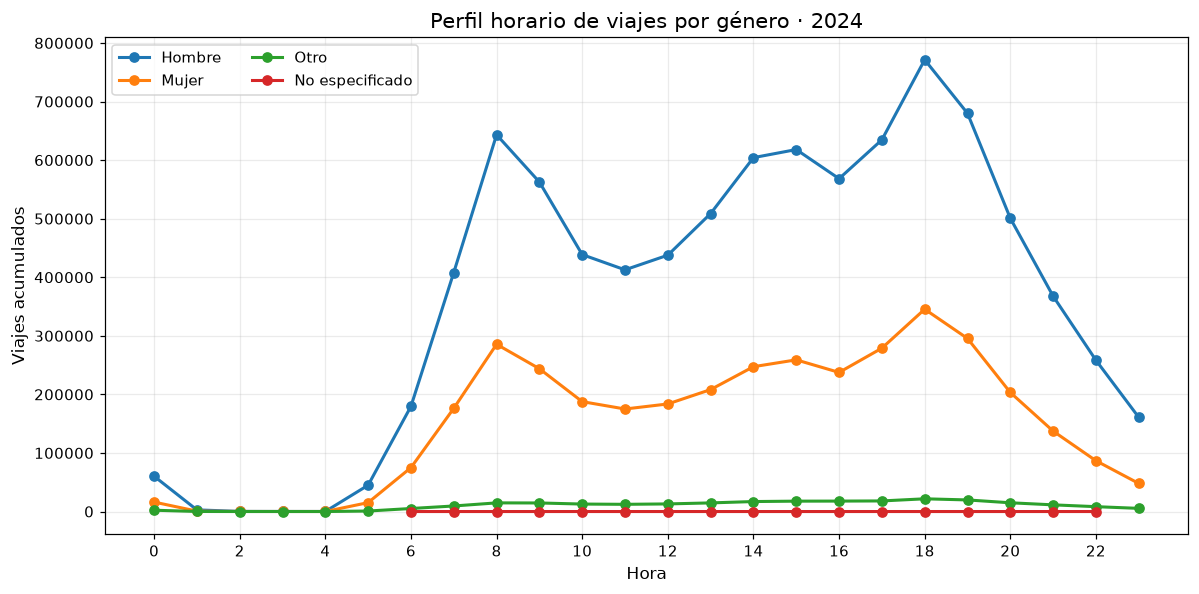

**Interpretación.** La hora con mayor volumen agregado en 2024 es alrededor de las **18:00**.  
**Relevancia.** Los picos horarios son centrales para redistribución y capacidad.  


In [14]:
mh=mensuales[mensuales.anio.eq(2024)&mensuales.hora_num.between(0,23)].groupby(['hora_num','genero'],as_index=False).viajes.sum()
fig,ax=plt.subplots();
for g in ['Hombre','Mujer','Otro','No especificado']:
    a=mh[mh.genero.eq(g)]
    if len(a): ax.plot(a.hora_num,a.viajes,marker='o',lw=2,label=g)
ax.set(title='Perfil horario de viajes por género · 2024',xlabel='Hora',ylabel='Viajes acumulados'); ax.set_xticks(range(0,24,2)); ax.legend(ncol=2); ax.grid(alpha=.25); plt.tight_layout(); plt.show()
h=mh.groupby('hora_num').viajes.sum(); hp=int(h.idxmax())
display(Markdown(f"""**Interpretación.** La hora con mayor volumen agregado en 2024 es alrededor de las **{hp:02d}:00**.  
**Relevancia.** Los picos horarios son centrales para redistribución y capacidad.  
"""))


---
## Pregunta 6 · ¿Cómo se distribuye la capacidad de estaciones entre alcaldías?

**Tipo:** barras de candados totales con número de estaciones.


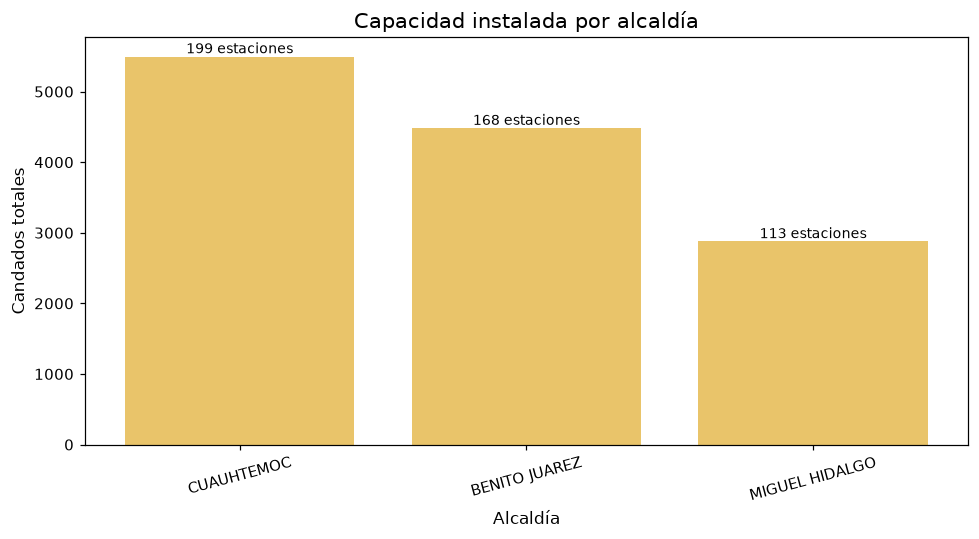

**Interpretación.** **CUAUHTEMOC** concentra la mayor capacidad del catálogo: **5,496 candados** en **199 estaciones**.  
**Relevancia.** La capacidad física condiciona retiros y arribos potenciales.  
**Limitación.** El catálogo contiene 480 estaciones en 3 alcaldías, mientras el archivo 2026 observa más códigos; la cobertura geográfica no es completa para toda la red 2026.

In [9]:
infra=estaciones.groupby('alcaldia',as_index=False).agg(estaciones=('num_cicloestacion','count'),candados=('candados','sum'),candados_promedio=('candados','mean')).sort_values('candados',ascending=False)
fig,ax=plt.subplots(figsize=(9,5)); bars=ax.bar(infra.alcaldia,infra.candados,color=COL['amarillo']); ax.set(title='Capacidad instalada por alcaldía',xlabel='Alcaldía',ylabel='Candados totales'); ax.tick_params(axis='x',rotation=15)
for b,n in zip(bars,infra.estaciones): ax.text(b.get_x()+b.get_width()/2,b.get_height(),f'{n} estaciones',ha='center',va='bottom',fontsize=9)
plt.tight_layout(); plt.show(); r=infra.iloc[0]
display(Markdown(f"""**Interpretación.** **{r.alcaldia}** concentra la mayor capacidad del catálogo: **{int(r.candados):,} candados** en **{int(r.estaciones)} estaciones**.  
**Relevancia.** La capacidad física condiciona retiros y arribos potenciales.  
**Limitación.** El catálogo contiene {len(estaciones)} estaciones en {estaciones.alcaldia.nunique()} alcaldías, mientras el archivo 2026 observa más códigos; la cobertura geográfica no es completa para toda la red 2026."""))


---
## Pregunta 7 · ¿Qué estaciones presentan mayor desequilibrio entre arribos y retiros?

**Tipo:** barras divergentes del balance `arribos − retiros`.


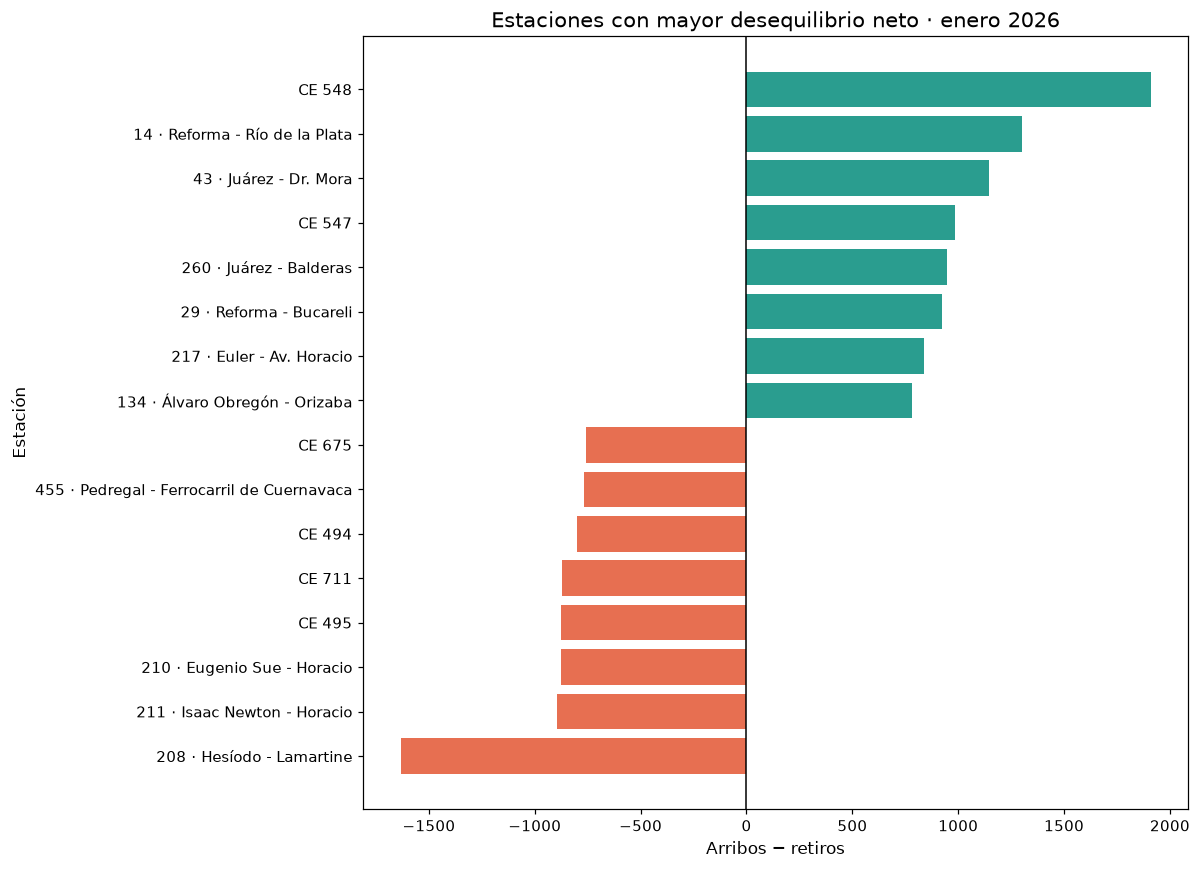

**Interpretación.** Mayor saldo positivo: **CE 548** (+1,908); mayor saldo negativo: **208 · Hesíodo - Lamartine** (-1,634).  
**Relevancia.** Aproxima la presión de redistribución de bicicletas.  
**Limitación.** Es un balance mensual; no indica la hora del desbalance ni movimientos logísticos del operador.

In [10]:
sal=detalle.groupby('origen_id').size().rename('retiros'); ent=detalle.groupby('destino_id').size().rename('arribos'); bal=pd.concat([sal,ent],axis=1).fillna(0); bal['neto']=bal.arribos-bal.retiros; bal=bal.reset_index().rename(columns={'index':'estacion_id'}); bal['nombre']=bal.estacion_id.map(nombre_map); bal['etiqueta']=np.where(bal.nombre.notna(),bal.estacion_id+' · '+bal.nombre.astype(str),'CE '+bal.estacion_id.astype(str)); ex=pd.concat([bal.nsmallest(8,'neto'),bal.nlargest(8,'neto')]).drop_duplicates('estacion_id').sort_values('neto')
fig,ax=plt.subplots(figsize=(11,8)); colors=[COL['rojo'] if x<0 else COL['verde'] for x in ex.neto]; ax.barh(ex.etiqueta,ex.neto,color=colors); ax.axvline(0,color='black',lw=1); ax.set(title='Estaciones con mayor desequilibrio neto · enero 2026',xlabel='Arribos − retiros',ylabel='Estación'); plt.tight_layout(); plt.show(); pos=bal.loc[bal.neto.idxmax()]; neg=bal.loc[bal.neto.idxmin()]
display(Markdown(f"""**Interpretación.** Mayor saldo positivo: **{pos.etiqueta}** (+{int(pos.neto):,}); mayor saldo negativo: **{neg.etiqueta}** ({int(neg.neto):,}).  
**Relevancia.** Aproxima la presión de redistribución de bicicletas.  
**Limitación.** Es un balance mensual; no indica la hora del desbalance ni movimientos logísticos del operador."""))
